In [1]:
import numpy as np
import matplotlib.pyplot as plt

print('NumPy version:', np.__version__)

NumPy version: 2.4.0


In [2]:
rng = np.random.default_rng(42)
scores = np.clip(rng.normal(loc=68, scale=12, size=100), 0, 100).round(1)
scores[:3] = [12.0, 15.0, 99.5]   # unusual values

print('Total students:', scores.size)
print('First 10 scores:', scores[:10])

Total students: 100
First 10 scores: [12.  15.  99.5 79.3 44.6 52.4 69.5 64.2 67.8 57.8]


In [3]:
mean_val   = np.mean(scores)
median_val = np.median(scores)
std_val    = np.std(scores)
min_val    = np.min(scores)
max_val    = np.max(scores)

print(f'Mean: {mean_val:.2f}')
print(f'Median: {median_val:.2f}')
print(f'Std dev: {std_val:.2f}')
print(f'Min: {min_val}  Max: {max_val}')

Mean: 66.62
Median: 67.60
Std dev: 12.30
Min: 12.0  Max: 99.5


In [4]:
diff = mean_val - median_val
print(f'Mean - Median = {diff:.2f}')
if abs(diff) < 0.1 * std_val:
    print('Roughly symmetric.')
elif diff > 0:
    print('Skewed right.')
else:
    print('Skewed left.')

Mean - Median = -0.98
Roughly symmetric.


In [5]:
q1, q2, q3 = np.percentile(scores, [25, 50, 75])
iqr = q3 - q1
print(q1, q2, q3, iqr)

60.25 67.6 74.42500000000001 14.175000000000011


In [6]:
lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
iqr_outliers = scores[(scores < lower) | (scores > upper)]
print('IQR outliers:', np.sort(iqr_outliers))

z = (scores - mean_val) / std_val
print('Z-score outliers:', np.sort(scores[np.abs(z) > 2]))

IQR outliers: [12.  15.  99.5]
Z-score outliers: [12.  15.  93.7 99.5]


C:\Users\harsh\AppData\Local\Temp\ipykernel_36720\3764086858.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot(scores, vert=False); ax[1].set_title('Box Plot')


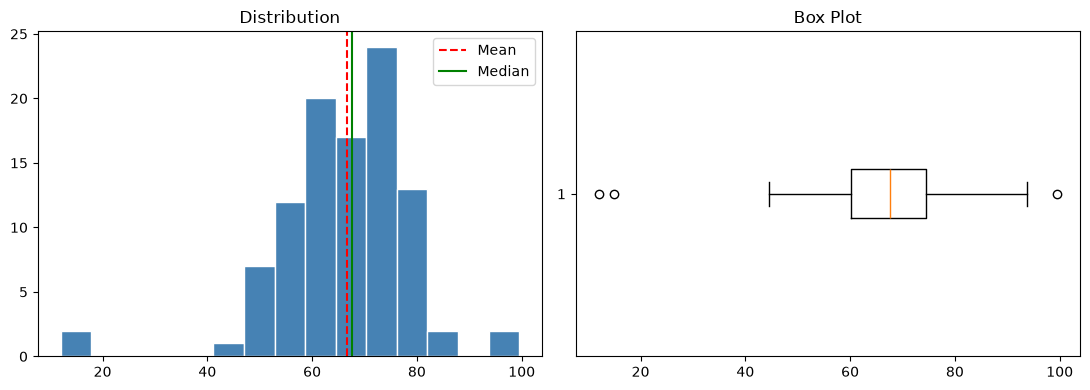

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(scores, bins=15, color='steelblue', edgecolor='white')
ax[0].axvline(mean_val, color='red', linestyle='--', label='Mean')
ax[0].axvline(median_val, color='green', label='Median')
ax[0].legend(); ax[0].set_title('Distribution')
ax[1].boxplot(scores, vert=False); ax[1].set_title('Box Plot')
plt.tight_layout(); plt.show()

In [8]:
print(f'1. Mean {mean_val:.2f} vs median {median_val:.2f}: close, so roughly symmetric.')
print(f'2. Std dev {std_val:.2f}: most scores fall in {mean_val-std_val:.1f}–{mean_val+std_val:.1f}.')
print(f'3. {iqr_outliers.size} outliers found (min {min_val}, max {max_val}).')

1. Mean 66.62 vs median 67.60: close, so roughly symmetric.
2. Std dev 12.30: most scores fall in 54.3–78.9.
3. 3 outliers found (min 12.0, max 99.5).
